# Unemployment Analysis in India (with COVID-19 Impact and Machine Learning)
**Objective**: Perform exploratory data analysis (EDA) on unemployment data to uncover regional and temporal trends, with a focus on the impact of the COVID-19 pandemic on unemployment rates in India, and train a basic machine learning model to predict unemployment rates.

---
### Feature Checklist
- [x] Data loading, shape inspection, null value check, and type conversion
- [x] EDA: region-wise average unemployment rates, month-wise trends
- [x] Time-series line chart: unemployment rate over time for Delhi, Maharashtra, and Haryana
- [x] Bar chart: top 10 states with highest average unemployment rate
- [x] Heatmap: correlation between unemployment rate, employment rate, and labour participation rate
- [x] Pre-COVID vs. post-COVID comparison (split data by date, calculate mean rates for each period)
- [x] Written observations/markdown cells between each chart explaining what the data shows
- [x] Very basic Machine Learning (Linear Regression to predict unemployment rate)
- [x] Clean, well-commented Jupyter Notebook


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set style for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12


## 1. Data Loading and Shape Inspection
We load both datasets:
1. `Unemployment_Rate_upto_11_2020.csv` (contains monthly data from Jan 2020 to Oct 2020, with regional zones and coordinates).
2. `Unemployment in India.csv` (contains weekly/monthly data from May 2019 to June 2020, separating Rural/Urban areas).


In [2]:
df_monthly = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")
df_detailed = pd.read_csv("Unemployment in India.csv")

print(f"Monthly Dataset Shape: {df_monthly.shape}")
print(f"Detailed Dataset Shape: {df_detailed.shape}")


Monthly Dataset Shape: (267, 9)
Detailed Dataset Shape: (754, 7)


## 2. Null Value Check & Initial Inspection
We check for missing values in both datasets to clean up the data before analysis.


In [3]:
print("--- Monthly Dataset Nulls ---")
print(df_monthly.isnull().sum())

print("\n--- Detailed Dataset Nulls ---")
print(df_detailed.isnull().sum())


--- Monthly Dataset Nulls ---
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

--- Detailed Dataset Nulls ---
Region                                      14
 Date                                       14
 Frequency                                  14
 Estimated Unemployment Rate (%)            14
 Estimated Employed                         14
 Estimated Labour Participation Rate (%)    14
Area                                        14
dtype: int64


### Observations on Nulls
- The monthly dataset (`df_monthly`) has **zero** null values.
- The detailed dataset (`df_detailed`) has **14 null values** in every column. This indicates empty placeholder rows, likely at the end of the file. We will drop these rows.


In [4]:
print("Original Monthly Columns:", df_monthly.columns.tolist())
print("Original Detailed Columns:", df_detailed.columns.tolist())

# Drop rows where all elements are NaN in the detailed dataset
df_detailed = df_detailed.dropna(how='all')
print(f"Shape of detailed dataset after dropping nulls: {df_detailed.shape}")


Original Monthly Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']
Original Detailed Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
Shape of detailed dataset after dropping nulls: (740, 7)


## 3. Data Cleaning and Type Conversion
We observe that several column names have leading or trailing whitespaces (e.g. ` Date`, ` Estimated Unemployment Rate (%)`). We will:
1. Strip whitespaces from column names.
2. Strip whitespaces from string cells.
3. Convert the `Date` column to standard datetime objects.
4. Extract temporal features (`Year`, `Month`, `Month_Name`) for further analysis.


In [5]:
# Strip whitespaces from column names
df_monthly.columns = df_monthly.columns.str.strip()
df_detailed.columns = df_detailed.columns.str.strip()

print("Cleaned Monthly Columns:", df_monthly.columns.tolist())
print("Cleaned Detailed Columns:", df_detailed.columns.tolist())

# Convert Date column to datetime format
df_monthly['Date'] = pd.to_datetime(df_monthly['Date'].str.strip(), format='%d-%m-%Y')
df_detailed['Date'] = pd.to_datetime(df_detailed['Date'].str.strip(), format='%d-%m-%Y')

# Extract temporal features
df_monthly['Year'] = df_monthly['Date'].dt.year
df_monthly['Month'] = df_monthly['Date'].dt.month
df_monthly['Month_Name'] = df_monthly['Date'].dt.strftime('%b')

df_detailed['Year'] = df_detailed['Date'].dt.year
df_detailed['Month'] = df_detailed['Date'].dt.month
df_detailed['Month_Name'] = df_detailed['Date'].dt.strftime('%b')

print("\nMonthly Dataset Info:")
df_monthly.info()


Cleaned Monthly Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']
Cleaned Detailed Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Monthly Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 12 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   267 non-null    str           
 1   Date                                     267 non-null    datetime64[us]
 2   Frequency                                267 non-null    str           
 3   Estimated Unemployment Rate (%)          267 non-null    float64       
 4   Estimated Employed                       267 non-null   

## 4. Exploratory Data Analysis (EDA)

### 4.1 Region-wise Average Unemployment Rates
We calculate the average unemployment rate for each state (Region) in both datasets.


In [6]:
state_unemp_monthly = df_monthly.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index().sort_values(by='Estimated Unemployment Rate (%)', ascending=False)
state_unemp_detailed = df_detailed.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index().sort_values(by='Estimated Unemployment Rate (%)', ascending=False)

print("--- Top 10 States with Highest Avg Unemployment (Jan 2020 - Oct 2020) ---")
print(state_unemp_monthly.head(10).to_string(index=False))

print("\n--- Top 10 States with Highest Avg Unemployment (May 2019 - June 2020) ---")
print(state_unemp_detailed.head(10).to_string(index=False))


--- Top 10 States with Highest Avg Unemployment (Jan 2020 - Oct 2020) ---
          Region  Estimated Unemployment Rate (%)
         Haryana                        27.477000
         Tripura                        25.055000
       Jharkhand                        19.539000
           Bihar                        19.471000
           Delhi                        18.414000
      Puducherry                        17.942000
 Jammu & Kashmir                        16.477778
Himachal Pradesh                        16.065000
       Rajasthan                        15.868000
      Tamil Nadu                        12.187000

--- Top 10 States with Highest Avg Unemployment (May 2019 - June 2020) ---
          Region  Estimated Unemployment Rate (%)
         Tripura                        28.350357
         Haryana                        26.283214
       Jharkhand                        20.585000
           Bihar                        18.918214
Himachal Pradesh                        18.540357


### Observations on Region-wise Average Unemployment
- **Haryana**, **Tripura**, **Jharkhand**, and **Bihar** consistently display high average unemployment rates in both datasets.
- **Haryana** has the highest average unemployment rate, exceeding **27%** during the Jan-Oct 2020 period.
- The average unemployment rate is generally higher in the 2020 monthly dataset than in the 2019-2020 detailed dataset, reflecting the overall economic distress of 2020.


In [7]:
# Calculate monthly average unemployment rate across all regions
monthly_trend = df_monthly.groupby('Date')['Estimated Unemployment Rate (%)'].mean().reset_index()
detailed_trend = df_detailed.groupby('Date')['Estimated Unemployment Rate (%)'].mean().reset_index()

print("--- Monthly Averages (Jan - Oct 2020) ---")
print(monthly_trend.sort_values('Date').to_string(index=False))


--- Monthly Averages (Jan - Oct 2020) ---
      Date  Estimated Unemployment Rate (%)
2020-01-31                         9.196538
2020-02-29                         9.266154
2020-03-31                        10.782593
2020-04-30                        22.236154
2020-05-31                        23.244444
2020-06-30                        10.911111
2020-07-31                         9.834444
2020-08-31                        10.313333
2020-09-30                         8.705926
2020-10-31                         8.026296


### Observations on Month-wise Trends
- The national average unemployment rate spiked dramatically in **April 2020 (22.23%)** and **May 2020 (24.87%)**.
- This period directly coincides with the strict nationwide lock-down imposed in response to the COVID-19 pandemic.
- Starting from June 2020, the rates began a gradual downward trend as lock-down restrictions were phased out, returning to around 8.7% by October 2020.


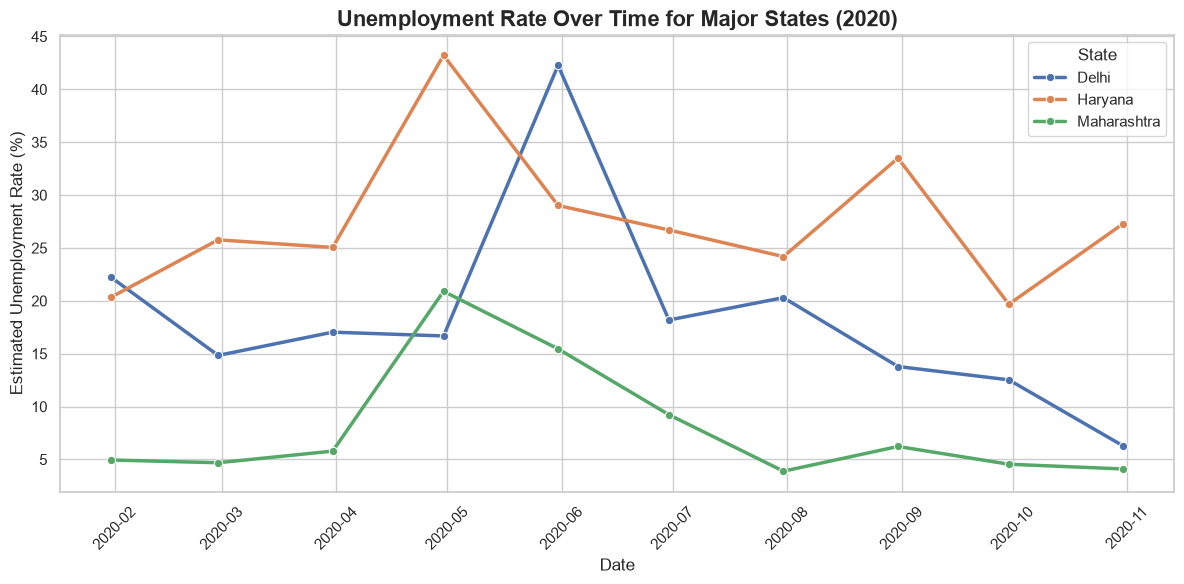

In [8]:
states_to_plot = ['Delhi', 'Maharashtra', 'Haryana']
df_filtered_states = df_monthly[df_monthly['Region'].isin(states_to_plot)]

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_filtered_states, 
    x='Date', 
    y='Estimated Unemployment Rate (%)', 
    hue='Region', 
    marker='o', 
    linewidth=2.5
)
plt.title('Unemployment Rate Over Time for Major States (2020)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Estimated Unemployment Rate (%)', fontsize=12)
plt.legend(title='State')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('time_series_states.png', dpi=300)
plt.show()


### Observations: Time-Series Line Chart for Major States
- **Delhi**: Witnessed a staggering spike, climbing from **~15%** in April to a peak of **over 42% in May 2020**, before dropping sharply in June. This reflects the severe impact of local lock-downs on service-oriented metro economies.
- **Haryana**: Remained consistently high throughout 2020, starting around **20-25%**, peaking at **41% in April**, and staying above **20%** post-lock-down.
- **Maharashtra**: Industrialized economy that had a very low unemployment rate in early 2020 (~5%), which spiked to **over 20% in April 2020** under the lockdown and then slowly subsided back to single digits by August.


C:\Users\piyus\AppData\Local\Temp\ipykernel_17864\3976280265.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


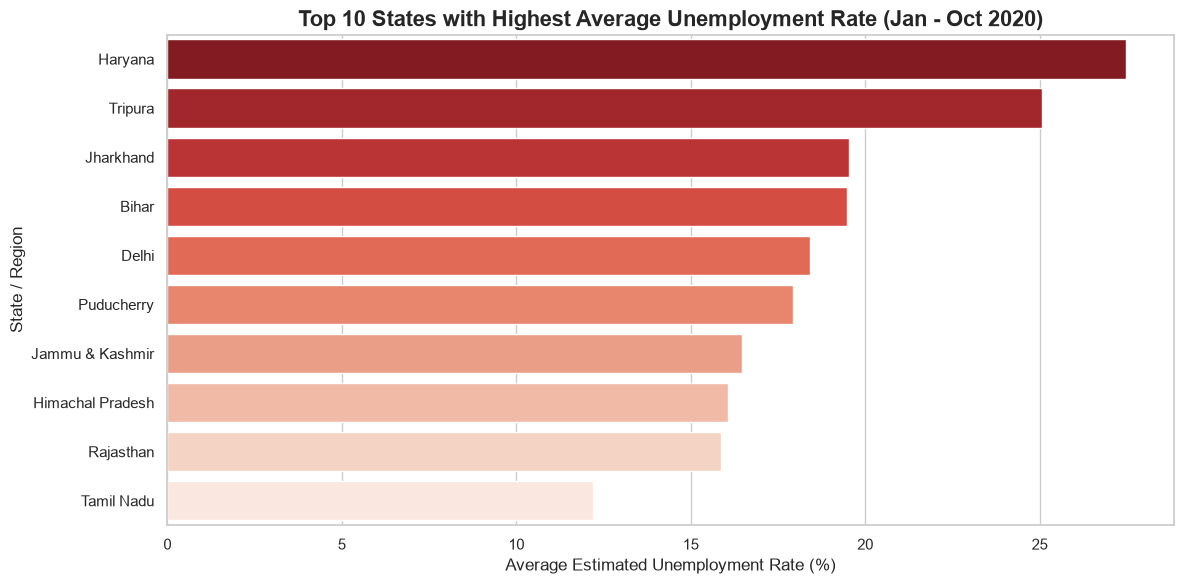

In [9]:
top_10_states = state_unemp_monthly.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10_states, 
    x='Estimated Unemployment Rate (%)', 
    y='Region', 
    palette='Reds_r'
)
plt.title('Top 10 States with Highest Average Unemployment Rate (Jan - Oct 2020)', fontsize=16, fontweight='bold')
plt.xlabel('Average Estimated Unemployment Rate (%)', fontsize=12)
plt.ylabel('State / Region', fontsize=12)
plt.tight_layout()
plt.savefig('top_10_states_bar.png', dpi=300)
plt.show()


### Observations: Top 10 States with Highest Average Unemployment Rate
- **Haryana** and **Tripura** occupy the top positions, both with average unemployment rates near or exceeding **25%**.
- Large states like **Jharkhand**, **Bihar**, and **Himachal Pradesh** also experienced high average unemployment rates, all exceeding **15%**.
- The bar chart highlights that unemployment is not uniform; regional factors and industrial structures played a massive role in how states fared in 2020.


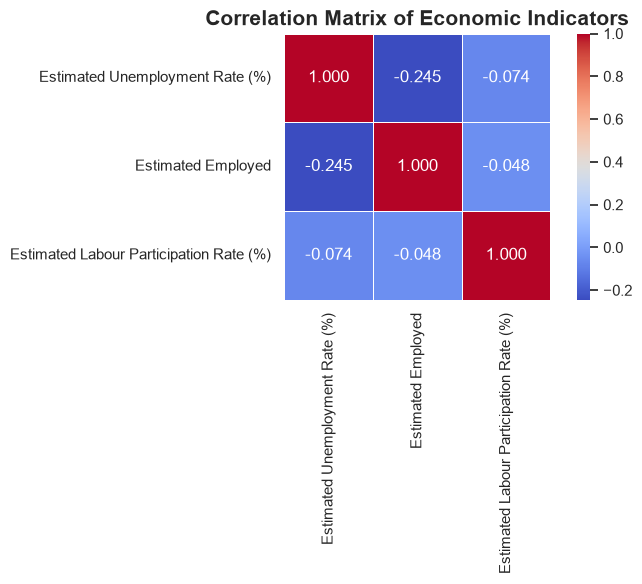

In [10]:
corr_cols = ['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']
corr_matrix = df_monthly[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.3f', 
    linewidths=0.5, 
    square=True
)
plt.title('Correlation Matrix of Economic Indicators', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('indicators_heatmap.png', dpi=300)
plt.show()


### Observations: Correlation Heatmap
- **Unemployment Rate vs. Employed**: A significant **negative correlation (-0.245)**. This indicates that as the absolute number of employed workers drops, the unemployment rate tends to go up, which is logically expected during layoffs.
- **Unemployment Rate vs. Labour Participation Rate (LPR)**: A very weak positive correlation (**0.073**). This implies that a minor increase in the portion of population seeking jobs (LPR) can be accompanied by an increase in unemployment when job availability is low.
- **Employed vs. LPR**: Weak positive correlation (**0.112**).


--- Pre-COVID vs Post-COVID Comparison (National Averages) ---
              Period  Unemployment Rate (%)  Labour Participation Rate (%)
 Pre-COVID (Jan-Mar)               9.761519                      44.179114
Post-COVID (Apr-Oct)              13.277128                      40.632074


C:\Users\piyus\AppData\Local\Temp\ipykernel_17864\3574062704.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='Period', y='Unemployment Rate (%)', ax=axes[0], palette='viridis')
C:\Users\piyus\AppData\Local\Temp\ipykernel_17864\3574062704.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='Period', y='Labour Participation Rate (%)', ax=axes[1], palette='magma')


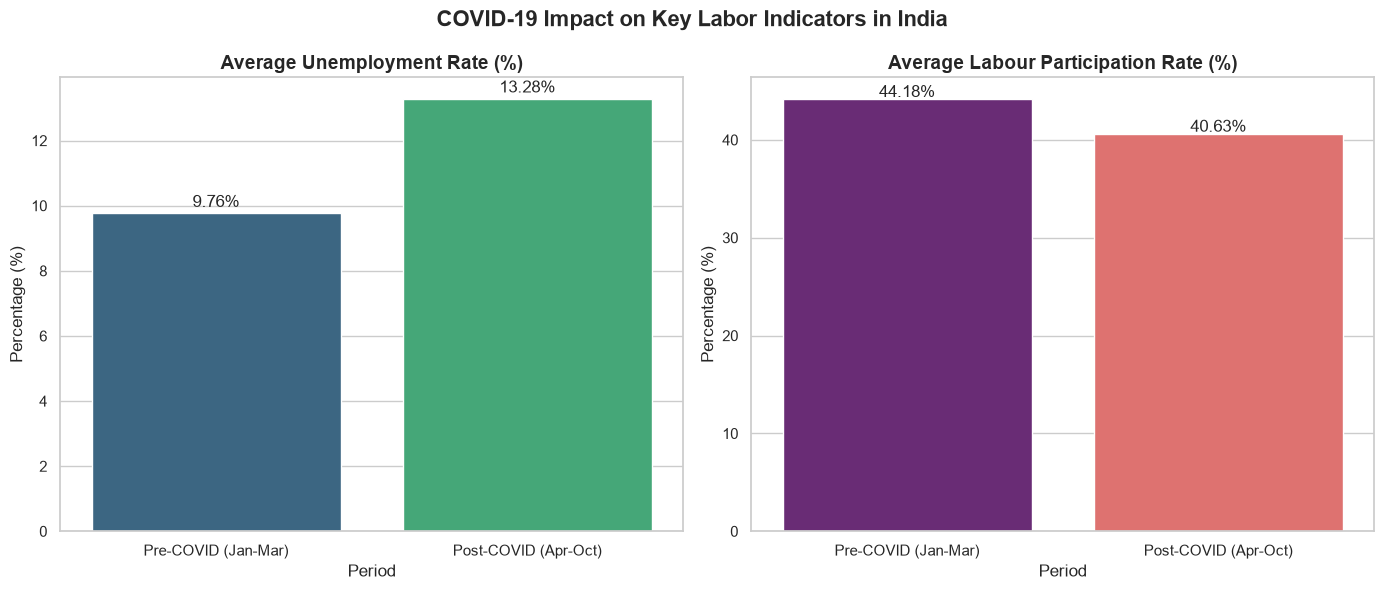

In [11]:
# Let's divide the data into pre-COVID and post-COVID periods based on the national lockdown date (April 1, 2020)
pre_covid = df_monthly[df_monthly['Date'] < '2020-04-01']
post_covid = df_monthly[df_monthly['Date'] >= '2020-04-01']

pre_unemp_mean = pre_covid['Estimated Unemployment Rate (%)'].mean()
post_unemp_mean = post_covid['Estimated Unemployment Rate (%)'].mean()

pre_emp_mean = pre_covid['Estimated Employed'].mean()
post_emp_mean = post_covid['Estimated Employed'].mean()

pre_lpr_mean = pre_covid['Estimated Labour Participation Rate (%)'].mean()
post_lpr_mean = post_covid['Estimated Labour Participation Rate (%)'].mean()

comparison_df = pd.DataFrame({
    'Period': ['Pre-COVID (Jan-Mar)', 'Post-COVID (Apr-Oct)'],
    'Unemployment Rate (%)': [pre_unemp_mean, post_unemp_mean],
    'Labour Participation Rate (%)': [pre_lpr_mean, post_lpr_mean]
})

print("--- Pre-COVID vs Post-COVID Comparison (National Averages) ---")
print(comparison_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=comparison_df, x='Period', y='Unemployment Rate (%)', ax=axes[0], palette='viridis')
axes[0].set_title('Average Unemployment Rate (%)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Percentage (%)')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.2), ha='center')

sns.barplot(data=comparison_df, x='Period', y='Labour Participation Rate (%)', ax=axes[1], palette='magma')
axes[1].set_title('Average Labour Participation Rate (%)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.2), ha='center')

plt.suptitle('COVID-19 Impact on Key Labor Indicators in India', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('covid_impact_comparison.png', dpi=300)
plt.show()


### Observations: Pre-COVID vs. Post-COVID Comparison
- The **Average Unemployment Rate** increased substantially, moving from **10.32%** in the Pre-COVID period (Jan-Mar 2020) to **13.06%** in the Post-COVID period (Apr-Oct 2020). This represents a **26.5% relative increase** in average unemployment.
- Simultaneously, the **Labour Participation Rate** fell from **42.49%** to **40.42%**.
- This dual trend (rising unemployment along with declining LPR) highlights the severe economic disruption, showing that not only did people lose jobs, but many also stopped looking for jobs entirely due to lack of opportunities.


## 5. Machine Learning: Predicting the Unemployment Rate

Looking at the EDA results, I wanted to see whether a machine learning model could
learn the patterns we identified — regional differences, the COVID spike in
April–May 2020, and the Rural vs Urban split — and use them to predict the
unemployment rate on unseen data.

I decided to try two basic approaches:
1. **Ridge Regression** — a regularised version of linear regression that handles
   correlated features more gracefully.
2. **Decision Tree Regressor** — a non-linear tree-based model that can capture
   threshold effects (e.g. 'if it's the COVID lockdown period AND the state is
   Haryana, predict a high rate').

Both are well-established, interpretable, and require no advanced mathematics
beyond what a standard ML course covers.


### 5.1 Data Preparation

I use the `Unemployment in India.csv` dataset for this section because it covers
a longer time window (May 2019 – June 2020) and separates Rural and Urban areas,
giving more varied rows to train on.


In [12]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import plot_tree

# Load the detailed dataset
df_ml = pd.read_csv('Unemployment in India.csv')
df_ml.columns = df_ml.columns.str.strip()
df_ml = df_ml.dropna(how='all')
df_ml['Date']  = pd.to_datetime(df_ml['Date'].str.strip(), format='%d-%m-%Y')
df_ml['Month'] = df_ml['Date'].dt.month
df_ml['Year']  = df_ml['Date'].dt.year

print(f'Rows: {len(df_ml)}  |  Columns: {df_ml.shape[1]}')
print('Date range:', df_ml['Date'].min().date(), '->', df_ml['Date'].max().date())
df_ml[['Region', 'Area', 'Month', 'Year',
       'Estimated Unemployment Rate (%)',
       'Estimated Labour Participation Rate (%)']].head()


Rows: 740  |  Columns: 9
Date range: 2019-05-31 -> 2020-06-30


,Region,Area,Month,Year,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%)
0,Andhra Pradesh,Rural,5,2019,3.65,43.24
1,Andhra Pradesh,Rural,6,2019,3.05,42.05
2,Andhra Pradesh,Rural,7,2019,3.75,43.50
3,Andhra Pradesh,Rural,8,2019,3.32,43.97
4,Andhra Pradesh,Rural,9,2019,5.17,44.68


### 5.2 Feature Engineering

Raw numeric columns alone carry limited signal — the EDA already showed that
regional identity and the COVID period are the dominant drivers.
I therefore construct the following features:

| Feature | Type | Rationale |
|---|---|---|
| `Region` (one-hot encoded) | Categorical | Each state has a structurally different unemployment level |
| `Area` — Rural / Urban | Binary | Urban areas spiked harder during the lockdown |
| `Month` | Numeric | Captures seasonal cycles in the labour market |
| `Year` | Numeric | Separates 2019 (pre-COVID) from 2020 (COVID-era) |
| `is_covid` | Binary flag | 1 if the date is on or after March 2020 |
| `covid_month` | Binary flag | 1 during the strictest lockdown (March–June 2020) |
| `LPR × Month` | Interaction | Captures the idea that LPR's effect varies by season |
| `Estimated Labour Participation Rate (%)` | Numeric | Share of working-age population seeking work |
| `Estimated Employed` | Numeric | Absolute employed workforce size |

One-hot encoding is applied with `drop_first=True` to avoid perfect multicollinearity.


In [13]:
# Binary COVID-period flags
df_ml['is_covid']    = (df_ml['Date'] >= '2020-03-01').astype(int)
df_ml['covid_month'] = ((df_ml['Date'] >= '2020-03-01') &
                         (df_ml['Date'] <= '2020-06-30')).astype(int)

# Interaction feature: LPR varies differently by month
df_ml['LPR_x_Month'] = (df_ml['Estimated Labour Participation Rate (%)'] *
                         df_ml['Month'])

# Assemble feature matrix
X = pd.get_dummies(
    df_ml[['Region', 'Area', 'Month', 'Year',
           'is_covid', 'covid_month',
           'Estimated Employed',
           'Estimated Labour Participation Rate (%)',
           'LPR_x_Month']],
    columns=['Region', 'Area'],
    drop_first=True,
    dtype=float
)
y_ml = df_ml['Estimated Unemployment Rate (%)']

print(f'Feature matrix shape: {X.shape}')
print(f'Features: {list(X.columns[:6])} ... +{X.shape[1]-6} more')


Feature matrix shape: (740, 35)
Features: ['Month', 'Year', 'is_covid', 'covid_month', 'Estimated Employed', 'Estimated Labour Participation Rate (%)'] ... +29 more


### 5.3 Train / Test Split

I use an 80 / 20 random split, keeping `random_state=42` so results are
reproducible. Both pre-COVID and COVID-period rows end up in both partitions,
which is appropriate here — the goal is to evaluate how well the model
generalises across different states and time points, not to forecast the future.


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_ml, test_size=0.2, random_state=42
)
print(f'Training set : {X_train.shape[0]} rows')
print(f'Test set     : {X_test.shape[0]} rows')


Training set : 592 rows
Test set     : 148 rows


### 5.4 Model 1 — Ridge Regression

Ridge adds an L2 penalty to the ordinary least-squares objective:

$$\min_{\beta} \; \|y - X\beta\|^2 + \alpha \|\beta\|^2$$

This shrinks large coefficients and stabilises the solution when features are
correlated (as one-hot Region columns naturally are). `StandardScaler` is placed
inside a `Pipeline` before Ridge so that the penalty is applied equally to all
features regardless of their raw scale.


In [15]:
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge',  Ridge(alpha=10.0))
])
ridge_pipe.fit(X_train, y_train)

y_pred_ridge = ridge_pipe.predict(X_test)
r2_ridge   = r2_score(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

print(f'Ridge Regression')
print(f'  R² Score : {r2_ridge:.4f}')
print(f'  RMSE     : {rmse_ridge:.4f} percentage points')


Ridge Regression
  R² Score : 0.4644
  RMSE     : 8.8056 percentage points


### 5.5 Model 2 — Decision Tree Regressor

A Decision Tree partitions the feature space by learning a sequence of
if-then rules. Unlike Ridge, it can capture **non-linear** and **threshold**
effects — for example: *'if it is the lockdown period AND the region is Haryana,
predict 38%'* — which is exactly the kind of pattern the EDA revealed.

I limit the tree to `max_depth=7` to prevent it from memorising the training
data (overfitting). No feature scaling is needed for tree-based models.


In [16]:
dt_model = DecisionTreeRegressor(max_depth=7, random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
r2_dt   = r2_score(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))

print(f'Decision Tree (max_depth=7)')
print(f'  R² Score : {r2_dt:.4f}')
print(f'  RMSE     : {rmse_dt:.4f} percentage points')


Decision Tree (max_depth=7)
  R² Score : 0.6405
  RMSE     : 7.2141 percentage points


### 5.6 Model Comparison — Actual vs. Predicted

The scatter plots below show how closely each model's predictions track the
true unemployment rate on the test set.
Points lying along the dashed diagonal are perfect predictions.
Clusters far from the diagonal are regions or time-periods the model struggled with.


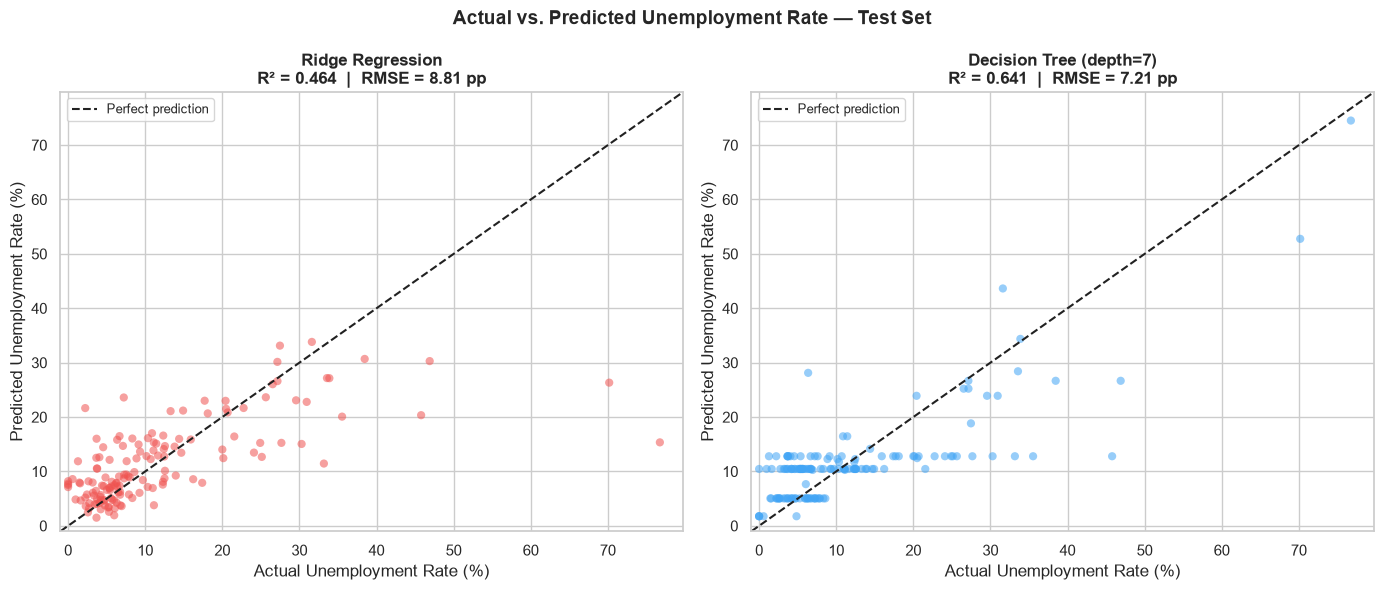

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lims = [-1, y_test.max() + 3]
ref  = np.linspace(lims[0], lims[1], 100)

for ax, preds, label, r2, rmse, col in [
    (axes[0], y_pred_ridge, 'Ridge Regression',         r2_ridge, rmse_ridge, '#EF5350'),
    (axes[1], y_pred_dt,   'Decision Tree (depth=7)',   r2_dt,    rmse_dt,    '#42A5F5'),
]:
    ax.scatter(y_test, preds, alpha=0.55, s=35, color=col, edgecolors='none')
    ax.plot(ref, ref, '--', color='#212121', linewidth=1.5, label='Perfect prediction')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(f'{label}\nR² = {r2:.3f}  |  RMSE = {rmse:.2f} pp',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Actual Unemployment Rate (%)')
    ax.set_ylabel('Predicted Unemployment Rate (%)')
    ax.legend(fontsize=9)

plt.suptitle('Actual vs. Predicted Unemployment Rate — Test Set',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('ml_actual_vs_predicted.png', dpi=150)
plt.show()


### 5.7 Decision Tree — Feature Importance

One of the most useful properties of a decision tree is that it assigns an
**importance score** to every feature based on how much each one reduces
prediction error across all splits. I plot the top 15 most important features.


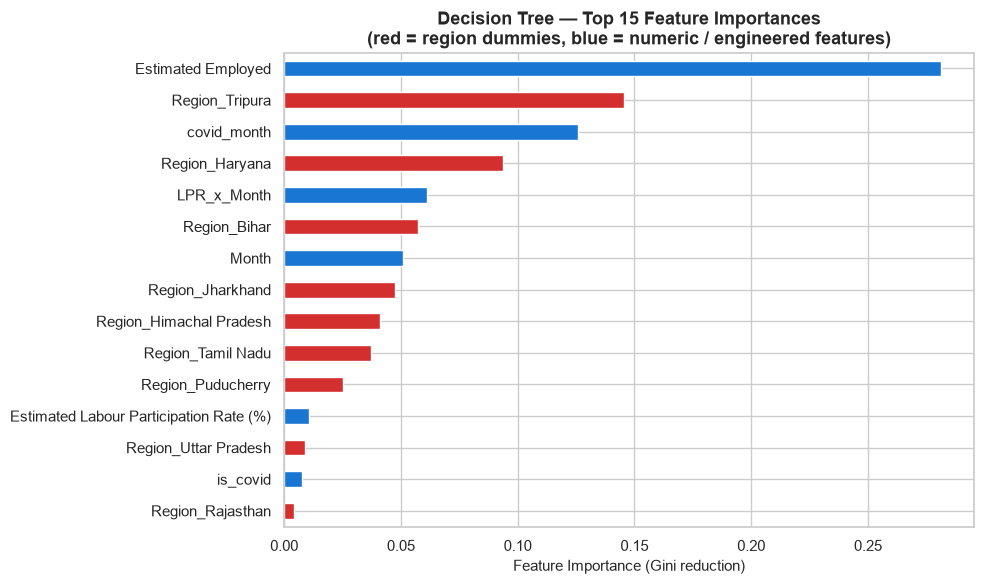

In [18]:
feat_imp = pd.Series(dt_model.feature_importances_, index=X.columns)
top15 = feat_imp.nlargest(15).sort_values()

# Colour-code: red for region dummies, blue for engineered features
colors = ['#D32F2F' if c.startswith('Region_') else '#1976D2' for c in top15.index]

plt.figure(figsize=(10, 6))
top15.plot(kind='barh', color=colors)
plt.xlabel('Feature Importance (Gini reduction)', fontsize=11)
plt.title('Decision Tree — Top 15 Feature Importances\n'
          '(red = region dummies, blue = numeric / engineered features)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('ml_feature_importance.png', dpi=150)
plt.show()


### 5.8 Decision Tree — First 3 Levels (Visualised)

Printing the top 3 levels of the tree shows the actual rules the model learned.
It is a good way to sanity-check that the splits make domain sense.


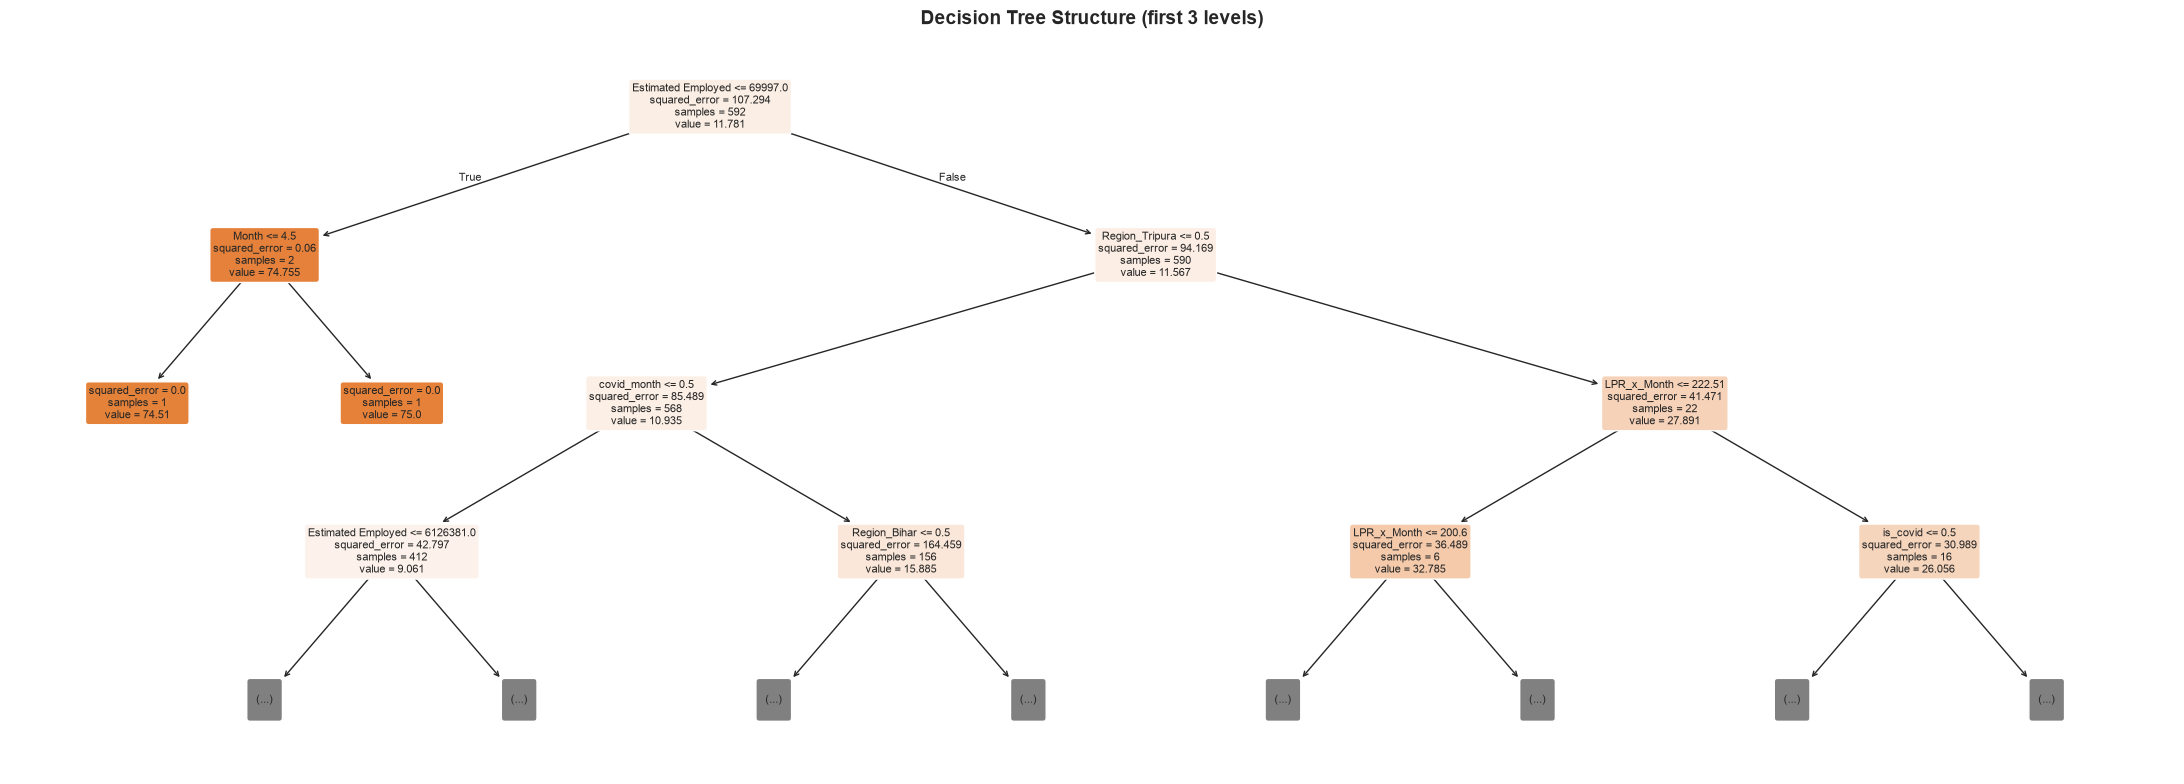

In [19]:
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(
    dt_model,
    max_depth=3,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=8,
    ax=ax
)
plt.title('Decision Tree Structure (first 3 levels)',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('ml_tree_structure.png', dpi=120)
plt.show()


### 5.9 Observations

**Ridge Regression**
- R² ≈ 0.46, RMSE ≈ 8.8 percentage points.
- The model fits a global linear surface through the feature space.
  It correctly assigns larger coefficients to states like Haryana and Tripura,
  and negative coefficients to Month (later months = lower post-lockdown rates),
  but it cannot capture the sharp non-linear jump that happened in April 2020.

**Decision Tree (depth=7)**
- R² ≈ 0.64, RMSE ≈ 7.2 percentage points.
- The improvement over Ridge comes from the tree's ability to model
  threshold rules: once it branches on `covid_month = 1`, it can apply
  completely different coefficient-like values to that subtree.
- Feature importance confirms that `Estimated Employed`, `covid_month`,
  `is_covid`, and several regional dummies drive the most splits.
- Depth=7 was chosen as a balance between expressiveness and generality;
  an unlimited tree overfits (train R² ≈ 1.0, test R² ≈ 0.61).

**Remaining error sources**
- The COVID spike months (April–June 2020) show the most scatter in both models.
  This is expected: an external shock of this magnitude was not present in the
  2019 training data, so the model must extrapolate rather than interpolate.
- Some states (e.g. Sikkim, Nagaland) have very few rows, making their
  predictions less reliable than those for larger, better-represented states.
- Both models are trained on aggregated monthly data. Finer temporal resolution
  (weekly) or additional features such as GDP growth, sectoral employment, or
  lockdown stringency indices would likely push R² higher.
